<a href="https://colab.research.google.com/github/derektorquette/estatistica-para-analise-de-dados-com-python/blob/main/2_tratamento_enem_2019_SP_reduzido.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# *PROJETO ANÁLISE ESTATÍSTICA DO ENEM 2019*

Este projeto analisa os resultados do ENEM no estado de São Paulo do ano de 2019.

Os dados foram extraídos do site do INEP:

http://inep.gov.br/microdados

## Importando Bibliotecas e Montando Drive




In [ ]:
import numpy as np # biblioteca de modelos matemáticos
import pandas as pd # biblioteca para manipulação dos dados

In [ ]:
from google.colab import drive # montar o drive, ler o arquivo diretamente
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
dados = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Estatística para Análise de Dados com Python/microdados_enem_2019_sp.csv',
                    sep=';', encoding='iso-8859-1')
print(dados.head())
# encoding: codificação de caracteres, normalmente utiliza-se o iso-8859-1, utf-8(nesse arquivo não funcionou), latin-1)

  NU_INSCRICAO  CO_MUNICIPIO_RESIDENCIA NO_MUNICIPIO_RESIDENCIA  \
0     1,90E+11                  3546801            Santa Isabel   
1     1,90E+11                  3538204             Pinhalzinho   
2     1,90E+11                  3550308               São Paulo   
3     1,90E+11                  3548708   São Bernardo do Campo   
4     1,90E+11                  3549409    São Joaquim da Barra   

   CO_UF_RESIDENCIA SG_UF_RESIDENCIA  NU_IDADE TP_SEXO  TP_ESTADO_CIVIL  \
0                35               SP        22       M                1   
1                35               SP        19       M                1   
2                35               SP        17       F                1   
3                35               SP        19       M                1   
4                35               SP        37       M                2   

   TP_COR_RACA  TP_NACIONALIDADE  ...  NU_NOTA_MT TP_LINGUA  \
0            3                 1  ...      6002.0         0   
1            3      

## Extração e Limpeza dos dados

In [ ]:
#pd.options.display.max_columns = 44

In [ ]:
dados.head() # cabeçalho, para maiores informações consultar o Dicionário de Microdados Enem

,NU_INSCRICAO,CO_MUNICIPIO_RESIDENCIA,NO_MUNICIPIO_RESIDENCIA,CO_UF_RESIDENCIA,SG_UF_RESIDENCIA,NU_IDADE,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,...,NU_NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,NU_NOTA_COMP1,NU_NOTA_COMP2,NU_NOTA_COMP3,NU_NOTA_COMP4,NU_NOTA_COMP5,NU_NOTA_REDACAO,Q025
0,"1,90E+11",3546801,Santa Isabel,35,SP,22,M,1,3,1,...,6002.0,0,1.0,160.0,200.0,180.0,200.0,200.0,940.0,B
1,"1,90E+11",3538204,Pinhalzinho,35,SP,19,M,1,3,1,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A
2,"1,90E+11",3550308,São Paulo,35,SP,17,F,1,3,1,...,7318.0,0,1.0,160.0,120.0,200.0,200.0,200.0,880.0,A
3,"1,90E+11",3548708,São Bernardo do Campo,35,SP,19,M,1,3,1,...,3932.0,1,1.0,80.0,160.0,120.0,100.0,100.0,560.0,B
4,"1,90E+11",3549409,São Joaquim da Barra,35,SP,37,M,2,1,1,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B


In [ ]:
# O número total de inscritos em São Paulo foi de 813772, sendo de 15,97% de todo o Brasil que foi de 5095308 inscritos.
dados.shape  # registros (linhas) e variáveis/atributos (colunas)

(813772, 44)

## Análise dos tipos de atributos

In [ ]:
# Análise dos tipos de atributos.
# object: strings
# int64: inteiros
# float64: reais
# complex: complexos
dados.dtypes

,0
NU_INSCRICAO,object
CO_MUNICIPIO_RESIDENCIA,int64
NO_MUNICIPIO_RESIDENCIA,object
CO_UF_RESIDENCIA,int64
SG_UF_RESIDENCIA,object
NU_IDADE,int64
TP_SEXO,object
TP_ESTADO_CIVIL,int64
TP_COR_RACA,int64
TP_NACIONALIDADE,int64


## Excluindo uma coluna

In [ ]:
dados1 = dados.drop(columns=['CO_MUNICIPIO_RESIDENCIA']) # é de boa prática gerar uma nova variável

In [ ]:
dados1.head() # cinco primeiras linhas

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,CO_UF_RESIDENCIA,SG_UF_RESIDENCIA,NU_IDADE,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,CO_MUNICIPIO_NASCIMENTO,...,NU_NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,NU_NOTA_COMP1,NU_NOTA_COMP2,NU_NOTA_COMP3,NU_NOTA_COMP4,NU_NOTA_COMP5,NU_NOTA_REDACAO,Q025
0,"1,90E+11",Santa Isabel,35,SP,22,M,1,3,1,1506500.0,...,6002.0,0,1.0,160.0,200.0,180.0,200.0,200.0,940.0,B
1,"1,90E+11",Pinhalzinho,35,SP,19,M,1,3,1,1503804.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A
2,"1,90E+11",São Paulo,35,SP,17,F,1,3,1,1501402.0,...,7318.0,0,1.0,160.0,120.0,200.0,200.0,200.0,880.0,A
3,"1,90E+11",São Bernardo do Campo,35,SP,19,M,1,3,1,3548708.0,...,3932.0,1,1.0,80.0,160.0,120.0,100.0,100.0,560.0,B
4,"1,90E+11",São Joaquim da Barra,35,SP,37,M,2,1,1,3549409.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B


## Excluindo mais de uma coluna

In [ ]:
dados1 = dados1.drop(columns=['CO_UF_RESIDENCIA','SG_UF_RESIDENCIA','CO_MUNICIPIO_NASCIMENTO'], ) # foram cortados os atributos

In [ ]:
dados1.head(10)

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,NU_IDADE,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,NO_MUNICIPIO_NASCIMENTO,CO_UF_NASCIMENTO,SG_UF_NASCIMENTO,...,NU_NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,NU_NOTA_COMP1,NU_NOTA_COMP2,NU_NOTA_COMP3,NU_NOTA_COMP4,NU_NOTA_COMP5,NU_NOTA_REDACAO,Q025
0,"1,90E+11",Santa Isabel,22,M,1,3,1,Santa Izabel do Pará,15.0,PA,...,6002.0,0,1.0,160.0,200.0,180.0,200.0,200.0,940.0,B
1,"1,90E+11",Pinhalzinho,19,M,1,3,1,Jacundá,15.0,PA,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A
2,"1,90E+11",São Paulo,17,F,1,3,1,Belém,15.0,PA,...,7318.0,0,1.0,160.0,120.0,200.0,200.0,200.0,880.0,A
3,"1,90E+11",São Bernardo do Campo,19,M,1,3,1,São Bernardo do Campo,35.0,SP,...,3932.0,1,1.0,80.0,160.0,120.0,100.0,100.0,560.0,B
4,"1,90E+11",São Joaquim da Barra,37,M,2,1,1,São Joaquim da Barra,35.0,SP,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B
5,"1,90E+11",Embu-Guaçu,17,F,1,3,1,Itacoatiara,13.0,AM,...,4192.0,0,1.0,120.0,120.0,120.0,120.0,80.0,560.0,B
6,"1,90E+11",São José dos Campos,28,F,1,1,1,Manaus,13.0,AM,...,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A
7,"1,90E+11",São José dos Campos,25,F,2,1,1,São José dos Campos,35.0,SP,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B
8,"1,90E+11",Guarulhos,23,F,1,1,1,São Paulo,35.0,SP,...,7961.0,0,1.0,160.0,200.0,180.0,180.0,160.0,880.0,B
9,"1,90E+11",São Paulo,19,F,1,3,1,Belém,15.0,PA,...,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B


In [ ]:
dados1 = dados1.drop(columns=['NO_MUNICIPIO_NASCIMENTO','CO_UF_NASCIMENTO','SG_UF_NASCIMENTO',
                              'TP_ANO_CONCLUIU','CO_MUNICIPIO_ESC','CO_UF_ESC','SG_UF_ESC'],) # mais cortes, para dúvidas consultar dicionário

In [ ]:
dados1.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,NU_IDADE,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,TP_ESCOLA,TP_ENSINO,...,NU_NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,NU_NOTA_COMP1,NU_NOTA_COMP2,NU_NOTA_COMP3,NU_NOTA_COMP4,NU_NOTA_COMP5,NU_NOTA_REDACAO,Q025
0,"1,90E+11",Santa Isabel,22,M,1,3,1,1,1,1.0,...,6002.0,0,1.0,160.0,200.0,180.0,200.0,200.0,940.0,B
1,"1,90E+11",Pinhalzinho,19,M,1,3,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A
2,"1,90E+11",São Paulo,17,F,1,3,1,2,3,1.0,...,7318.0,0,1.0,160.0,120.0,200.0,200.0,200.0,880.0,A
3,"1,90E+11",São Bernardo do Campo,19,M,1,3,1,2,2,1.0,...,3932.0,1,1.0,80.0,160.0,120.0,100.0,100.0,560.0,B
4,"1,90E+11",São Joaquim da Barra,37,M,2,1,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B


In [ ]:
dados1 = dados1.drop(columns=['TP_DEPENDENCIA_ADM_ESC','TP_LOCALIZACAO_ESC','TP_SIT_FUNC_ESC'],) # foram feitas várias limpezas gradativas como exemplo

In [ ]:
dados1.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,NU_IDADE,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,TP_ESCOLA,TP_ENSINO,...,NU_NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,NU_NOTA_COMP1,NU_NOTA_COMP2,NU_NOTA_COMP3,NU_NOTA_COMP4,NU_NOTA_COMP5,NU_NOTA_REDACAO,Q025
0,"1,90E+11",Santa Isabel,22,M,1,3,1,1,1,1.0,...,6002.0,0,1.0,160.0,200.0,180.0,200.0,200.0,940.0,B
1,"1,90E+11",Pinhalzinho,19,M,1,3,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A
2,"1,90E+11",São Paulo,17,F,1,3,1,2,3,1.0,...,7318.0,0,1.0,160.0,120.0,200.0,200.0,200.0,880.0,A
3,"1,90E+11",São Bernardo do Campo,19,M,1,3,1,2,2,1.0,...,3932.0,1,1.0,80.0,160.0,120.0,100.0,100.0,560.0,B
4,"1,90E+11",São Joaquim da Barra,37,M,2,1,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B


In [ ]:
dados1.shape # dos 44 atributos restaram apenas 29.

(813772, 30)

## Corrigindo erros nas notas

In [ ]:
dados1.loc[:,'NU_NOTA_CN'] /= 10 #localizar todas as linhas e coluna específica para corrigir o número

In [ ]:
dados1.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,NU_IDADE,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,TP_ESCOLA,TP_ENSINO,...,NU_NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,NU_NOTA_COMP1,NU_NOTA_COMP2,NU_NOTA_COMP3,NU_NOTA_COMP4,NU_NOTA_COMP5,NU_NOTA_REDACAO,Q025
0,"1,90E+11",Santa Isabel,22,M,1,3,1,1,1,1.0,...,6002.0,0,1.0,160.0,200.0,180.0,200.0,200.0,940.0,B
1,"1,90E+11",Pinhalzinho,19,M,1,3,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A
2,"1,90E+11",São Paulo,17,F,1,3,1,2,3,1.0,...,7318.0,0,1.0,160.0,120.0,200.0,200.0,200.0,880.0,A
3,"1,90E+11",São Bernardo do Campo,19,M,1,3,1,2,2,1.0,...,3932.0,1,1.0,80.0,160.0,120.0,100.0,100.0,560.0,B
4,"1,90E+11",São Joaquim da Barra,37,M,2,1,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B


In [ ]:
dados1.loc[:,'NU_NOTA_CH'] /= 10 # corrigindo os números das outras colunas
dados1.loc[:,'NU_NOTA_LC'] /= 10
dados1.loc[:,'NU_NOTA_MT'] /= 10

In [ ]:
dados1.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,NU_IDADE,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,TP_ESCOLA,TP_ENSINO,...,NU_NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,NU_NOTA_COMP1,NU_NOTA_COMP2,NU_NOTA_COMP3,NU_NOTA_COMP4,NU_NOTA_COMP5,NU_NOTA_REDACAO,Q025
0,"1,90E+11",Santa Isabel,22,M,1,3,1,1,1,1.0,...,600.2,0,1.0,160.0,200.0,180.0,200.0,200.0,940.0,B
1,"1,90E+11",Pinhalzinho,19,M,1,3,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A
2,"1,90E+11",São Paulo,17,F,1,3,1,2,3,1.0,...,731.8,0,1.0,160.0,120.0,200.0,200.0,200.0,880.0,A
3,"1,90E+11",São Bernardo do Campo,19,M,1,3,1,2,2,1.0,...,393.2,1,1.0,80.0,160.0,120.0,100.0,100.0,560.0,B
4,"1,90E+11",São Joaquim da Barra,37,M,2,1,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B


##Renomeando Variáveis (colunas)

In [ ]:
dados1 = dados1.rename(columns={'NU_NOTA_REDACAO': 'NOTA_REDACAO'})

In [ ]:
dados1 = dados1.rename(columns={'NU_NOTA_CN': 'NOTA_CN','NU_NOTA_CH': 'NOTA_CH',
                                'NU_NOTA_LC': 'NOTA_LC','NU_NOTA_MT': 'NOTA_MT'})

In [ ]:
dados1 = dados1.rename(columns={'NU_NOTA_COMP1': 'COMP1','NU_NOTA_COMP2': 'COMP2',
                                'NU_NOTA_COMP3': 'COMP3','NU_NOTA_COMP4': 'COMP4',
                                'NU_NOTA_COMP5':'COMP5'})

In [ ]:
dados1 = dados1.rename(columns={'NU_IDADE': 'IDADE','TP_SEXO': 'SEXO',
                                'TP_COR_RACA': 'RACA','Q025': 'INTERNET',
                                'TP_ESCOLA':'ESCOLA'})

In [ ]:
dados1.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,IDADE,SEXO,TP_ESTADO_CIVIL,RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,ESCOLA,TP_ENSINO,...,NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO,INTERNET
0,"1,90E+11",Santa Isabel,22,M,1,3,1,1,1,1.0,...,600.2,0,1.0,160.0,200.0,180.0,200.0,200.0,940.0,B
1,"1,90E+11",Pinhalzinho,19,M,1,3,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A
2,"1,90E+11",São Paulo,17,F,1,3,1,2,3,1.0,...,731.8,0,1.0,160.0,120.0,200.0,200.0,200.0,880.0,A
3,"1,90E+11",São Bernardo do Campo,19,M,1,3,1,2,2,1.0,...,393.2,1,1.0,80.0,160.0,120.0,100.0,100.0,560.0,B
4,"1,90E+11",São Joaquim da Barra,37,M,2,1,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B


##Renomeando Registros (linhas)

In [ ]:
dados1["RACA"] = dados1["RACA"].replace({0:"nao_declarado", 1:"branca", 2:"preta", 3:"parda", 4:"amarela", 5:"indigena"}) #fazer alteração na coluna raça

In [ ]:
dados1.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,IDADE,SEXO,TP_ESTADO_CIVIL,RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,ESCOLA,TP_ENSINO,...,NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO,INTERNET
0,"1,90E+11",Santa Isabel,22,M,1,parda,1,1,1,1.0,...,600.2,0,1.0,160.0,200.0,180.0,200.0,200.0,940.0,B
1,"1,90E+11",Pinhalzinho,19,M,1,parda,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A
2,"1,90E+11",São Paulo,17,F,1,parda,1,2,3,1.0,...,731.8,0,1.0,160.0,120.0,200.0,200.0,200.0,880.0,A
3,"1,90E+11",São Bernardo do Campo,19,M,1,parda,1,2,2,1.0,...,393.2,1,1.0,80.0,160.0,120.0,100.0,100.0,560.0,B
4,"1,90E+11",São Joaquim da Barra,37,M,2,branca,1,1,1,1.0,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B


In [ ]:
# OUTRA MANEIRA
# dados1['RACA'] = dados1['RACA'].replace([0,1,2,3,4,5], ['Não Declarado','Branca','Preta','Parda','Amarela','Indígena'])

In [ ]:
dados1["TP_LINGUA"] = dados1["TP_LINGUA"].replace({0:"Inglês", 1:"Espanhol"})

In [ ]:
dados1["ESCOLA"] = dados1["ESCOLA"].replace({1:"não_respondeu", 2:"pública", 3:"privada", 4:"exterior"})

In [ ]:
dados1["INTERNET"] = dados1["INTERNET"].replace({"A":"Não", "B":"Sim"})

In [ ]:
dados1["TP_ENSINO"] = dados1["TP_ENSINO"].replace({1:"ensino_regular", 2:"educacao_especial", 3:"eja"})

In [ ]:
dados1.head(2)

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,IDADE,SEXO,TP_ESTADO_CIVIL,RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,ESCOLA,TP_ENSINO,...,NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO,INTERNET
0,"1,90E+11",Santa Isabel,22,M,1,parda,1,1,não_respondeu,ensino_regular,...,600.2,Inglês,1.0,160.0,200.0,180.0,200.0,200.0,940.0,Sim
1,"1,90E+11",Pinhalzinho,19,M,1,parda,1,1,não_respondeu,ensino_regular,...,NaN,Espanhol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Não


## Análise Exploratória e Transformação dos dados

**Análise das idades**

In [ ]:
dados1['IDADE'].value_counts() # contagem dos valores de idade


,count
IDADE,
17,219313
18,147548
19,81236
16,59316
20,53009
...,...
91,1
4,1
3,1


In [ ]:
dados1['IDADE'].value_counts().sort_index() # contagem dos valores em ordem

,count
IDADE,
2,1
3,1
4,1
5,2
6,2
...,...
80,2
81,3
82,2


In [ ]:
# Para ver todas as linhas, primeiro transforme num Dataframe:
idade = pd.DataFrame(dados1['IDADE'].value_counts().sort_index())

In [ ]:
# Configura o Pandas para observar 10 linhas
pd.set_option('display.max_rows', 10)

In [ ]:
idade.head(10)

,count
IDADE,
2,1
3,1
4,1
5,2
6,2
7,3
8,6
12,6
13,29


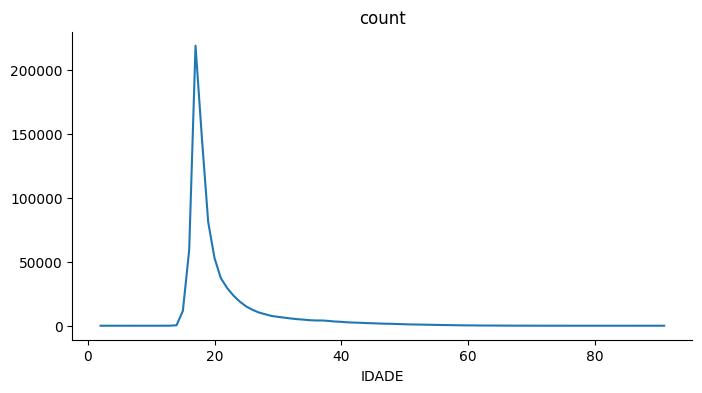

In [ ]:
# @title count

from matplotlib import pyplot as plt
idade['count'].plot(kind='line', figsize=(8, 4), title='count')
plt.gca().spines[['top', 'right']].set_visible(False)

Alguns valores estranhos e curiosos: idades menores que 12 anos e maiores de 80 anos.

In [ ]:
menores_12 = dados1.query('IDADE < 12')['NO_MUNICIPIO_RESIDENCIA'].value_counts() # comparar duas colunas

In [ ]:
# Inscrições com idade abaixo de 12 anos serão excluídos devido a alta probabilidade de erro.
menores_12

,count
NO_MUNICIPIO_RESIDENCIA,
São Paulo,5
Tambaú,1
Ribeirão Preto,1
Bálsamo,1
São Bernardo do Campo,1
...,...
Santana de Parnaíba,1
Vargem Grande Paulista,1
Auriflama,1


In [ ]:
dados_maiores_11 = dados1.loc[dados1.IDADE > 11] #loc, função localizar

In [ ]:
dados_maiores_11.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,IDADE,SEXO,TP_ESTADO_CIVIL,RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,ESCOLA,TP_ENSINO,...,NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO,INTERNET
0,"1,90E+11",Santa Isabel,22,M,1,parda,1,1,não_respondeu,ensino_regular,...,600.2,Inglês,1.0,160.0,200.0,180.0,200.0,200.0,940.0,Sim
1,"1,90E+11",Pinhalzinho,19,M,1,parda,1,1,não_respondeu,ensino_regular,...,NaN,Espanhol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Não
2,"1,90E+11",São Paulo,17,F,1,parda,1,2,privada,ensino_regular,...,731.8,Inglês,1.0,160.0,120.0,200.0,200.0,200.0,880.0,Não
3,"1,90E+11",São Bernardo do Campo,19,M,1,parda,1,2,pública,ensino_regular,...,393.2,Espanhol,1.0,80.0,160.0,120.0,100.0,100.0,560.0,Sim
4,"1,90E+11",São Joaquim da Barra,37,M,2,branca,1,1,não_respondeu,ensino_regular,...,NaN,Espanhol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sim


In [ ]:
dados_maiores_11['IDADE'].value_counts().sort_index() # fazer contagem e colocar em ordem

,count
IDADE,
12,6
13,29
14,355
15,11583
16,59316
...,...
80,2
81,3
82,2


**Treineiros**

In [ ]:
dados_maiores_11.query('IN_TREINEIRO == 1')['IN_TREINEIRO'].value_counts() # consultar dicionário

,count
IN_TREINEIRO,
1,93988


In [ ]:
treineiros = dados_maiores_11.loc[dados_maiores_11.IN_TREINEIRO == 1] # buscar treineiros

In [ ]:
treineiros.head() # tabela só com treineiros

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,IDADE,SEXO,TP_ESTADO_CIVIL,RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,ESCOLA,TP_ENSINO,...,NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO,INTERNET
20,"1,90E+11",Santos,15,F,1,parda,1,3,não_respondeu,NaN,...,573.2,Inglês,1.0,140.0,120.0,120.0,100.0,80.0,560.0,Sim
21,"1,90E+11",Panorama,16,F,1,parda,1,3,não_respondeu,NaN,...,NaN,Espanhol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Não
106,"1,90E+11",São Paulo,16,F,1,branca,1,3,não_respondeu,NaN,...,532.6,Inglês,1.0,120.0,120.0,120.0,100.0,80.0,540.0,Sim
109,"1,90E+11",Águas de Lindóia,16,M,1,branca,1,3,não_respondeu,NaN,...,NaN,Espanhol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sim
159,"1,90E+11",Águas de Lindóia,15,M,1,branca,1,3,não_respondeu,NaN,...,NaN,Inglês,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sim


In [ ]:
treineiros.to_csv('treineiros_enem_2019_sp.csv', encoding = 'iso-8859-1', index = False)

In [ ]:
# Separação entre os treineiros e os vestibulandos
vestibulandos = dados_maiores_11.loc[dados_maiores_11.IN_TREINEIRO == 0]

In [ ]:
vestibulandos.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,IDADE,SEXO,TP_ESTADO_CIVIL,RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,ESCOLA,TP_ENSINO,...,NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO,INTERNET
0,"1,90E+11",Santa Isabel,22,M,1,parda,1,1,não_respondeu,ensino_regular,...,600.2,Inglês,1.0,160.0,200.0,180.0,200.0,200.0,940.0,Sim
1,"1,90E+11",Pinhalzinho,19,M,1,parda,1,1,não_respondeu,ensino_regular,...,NaN,Espanhol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Não
2,"1,90E+11",São Paulo,17,F,1,parda,1,2,privada,ensino_regular,...,731.8,Inglês,1.0,160.0,120.0,200.0,200.0,200.0,880.0,Não
3,"1,90E+11",São Bernardo do Campo,19,M,1,parda,1,2,pública,ensino_regular,...,393.2,Espanhol,1.0,80.0,160.0,120.0,100.0,100.0,560.0,Sim
4,"1,90E+11",São Joaquim da Barra,37,M,2,branca,1,1,não_respondeu,ensino_regular,...,NaN,Espanhol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sim


In [ ]:
vestibulandos.shape

(719768, 30)

##Análise das presenças

In [ ]:
vestibulandos['TP_PRESENCA_CN'].value_counts()

,count
TP_PRESENCA_CN,
1,500805
0,218693
2,270


In [ ]:
vestibulandos['TP_PRESENCA_MT'].value_counts()

,count
TP_PRESENCA_MT,
1,500805
0,218693
2,270


In [ ]:
vestibulandos['TP_PRESENCA_CH'].value_counts()

,count
TP_PRESENCA_CH,
1,533142
0,185969
2,657


In [ ]:
vestibulandos['TP_PRESENCA_LC'].value_counts()

,count
TP_PRESENCA_LC,
1,533142
0,185969
2,657


**RESUMO DA PRESENÇA NAS PROVAS:**

- Ciências da Natureza: 500805 presentes, 218693 faltaram e 270 eliminados.

- Ciências Humanas: 533142 presentes, 185969 faltaram e 657 eliminados.

- Linguagens e Códigos: 533142 presentes, 185969 faltaram e 657 eliminados.

- Matemática: 500805 presentes, 218693 faltaram e 270 eliminados.







In [ ]:
vestibulandos['TP_STATUS_REDACAO'].value_counts().sort_index()

,count
TP_STATUS_REDACAO,
1.0,519763
2.0,913
3.0,1417
4.0,5513
6.0,3626
7.0,543
8.0,828
9.0,539


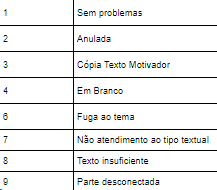

##Valores Ausentes

In [ ]:
vestibulandos['IDADE'].isnull().sum() # verifica valores ausentes e soma

np.int64(0)

In [ ]:
provas1 = ['NOTA_REDACAO','NOTA_CN','NOTA_MT','NOTA_LC','NOTA_CH']

In [ ]:
# Registros NAN nas notas
vestibulandos[provas1].isnull().sum()

,0
NOTA_REDACAO,186626
NOTA_CN,218963
NOTA_MT,218963
NOTA_LC,186626
NOTA_CH,186626


In [ ]:
vestibulandos_classificados = vestibulandos.loc[vestibulandos.TP_PRESENCA_CH == 1]
vestibulandos_classificados = vestibulandos_classificados.loc[vestibulandos_classificados.TP_PRESENCA_MT == 1]

In [ ]:
vestibulandos_classificados['TP_PRESENCA_MT'].value_counts()

,count
TP_PRESENCA_MT,
1,499940


In [ ]:
vestibulandos_classificados['TP_PRESENCA_CH'].value_counts()

,count
TP_PRESENCA_CH,
1,499940


In [ ]:
vestibulandos_classificados['TP_PRESENCA_CN'].value_counts()

,count
TP_PRESENCA_CN,
1,499940


In [ ]:
vestibulandos_classificados['TP_PRESENCA_LC'].value_counts()

,count
TP_PRESENCA_LC,
1,499940


In [ ]:
vestibulandos_classificados[provas1].isnull().sum()

,0
NOTA_REDACAO,0
NOTA_CN,0
NOTA_MT,0
NOTA_LC,0
NOTA_CH,0


##Notas zeros na Redação

In [ ]:
from collections import Counter
dict(Counter(vestibulandos_classificados['NOTA_REDACAO']))

{940.0: 4688,
 880.0: 7676,
 560.0: 35741,
 580.0: 33062,
 540.0: 25538,
 900.0: 5921,
 520.0: 24551,
 500.0: 17102,
 680.0: 19520,
 660.0: 18451,
 760.0: 12859,
 860.0: 6502,
 480.0: 19617,
 640.0: 27623,
 720.0: 15214,
 600.0: 37197,
 820.0: 7810,
 340.0: 5464,
 0.0: 9181,
 920.0: 6540,
 780.0: 9236,
 400.0: 7232,
 740.0: 10931,
 320.0: 8113,
 840.0: 9047,
 800.0: 10677,
 700.0: 13502,
 460.0: 13045,
 360.0: 7023,
 620.0: 28059,
 980.0: 978,
 440.0: 11950,
 420.0: 6555,
 380.0: 4453,
 280.0: 4734,
 300.0: 5418,
 960.0: 3057,
 200.0: 312,
 260.0: 2634,
 180.0: 105,
 240.0: 1841,
 220.0: 664,
 40.0: 1,
 140.0: 20,
 160.0: 65,
 120.0: 16,
 100.0: 5,
 60.0: 4,
 1000.0: 5,
 80.0: 1}

In [ ]:
vestibulandos_classificados.query('NOTA_REDACAO == 0')['NOTA_REDACAO'].value_counts()

,count
NOTA_REDACAO,
0.0,9181


In [ ]:
vestibulandos_classificados.query('COMP1 == 0')['COMP1'].value_counts()

,count
COMP1,
0.0,9188


In [ ]:
vestibulandos_classificados.query('COMP2 == 0')['COMP2'].value_counts()

,count
COMP2,
0.0,9181


In [ ]:
vestibulandos_classificados.query('COMP3 == 0')['COMP3'].value_counts()

,count
COMP3,
0.0,9197


In [ ]:
vestibulandos_classificados.query('COMP4 == 0')['COMP4'].value_counts()

,count
COMP4,
0.0,9194


In [ ]:
vestibulandos_classificados.query('COMP5 == 0')['COMP5'].value_counts()

,count
COMP5,
0.0,73330


**NOTAS ZEROS EM REDAÇÃO:**

REDAÇÃO (final): 9181 notas zeros devido a não cumprimento das regras ou tirou zero em todos os cinco componentes.

COMPONENTE 1(Demonstrar domínio da modalidade escrita formal da Língua Portuguesa.): 9188 notas zeros somente neste item.

COMPONENTE 2 (Compreender a proposta de redação e aplicar conceitos das várias áreas de conhecimento para desenvolver o tema, dentro dos limites estruturais do texto dissertativo-argumentativo em prosa): 9181.

COMPONENTE 3 (Selecionar, relacionar, organizar e interpretar informações, fatos, opiniões e argumentos em defesa de um ponto de vista): 9197 notas zeros somente neste item.

COMPONENTE 4 (Demonstrar conhecimento dos mecanismos linguísticos necessários para a construção da argumentação.): 9194 notas zeros somente neste item.

COMPONENTE 5 (Elaborar proposta de intervenção para o problema abordado, respeitando os direitos humanos): 73330 notas zeros somente neste item.


In [ ]:
vestibulandos_classificados.query('NOTA_CH == 0')['NOTA_CH'].value_counts()

,count
NOTA_CH,
0.0,343


In [ ]:
vestibulandos_classificados.query('NOTA_CN == 0')['NOTA_CN'].value_counts()

,count
NOTA_CN,
0.0,36


In [ ]:
vestibulandos_classificados.query('NOTA_LC == 0')['NOTA_LC'].value_counts()

,count
NOTA_LC,
0.0,135


In [ ]:
vestibulandos_classificados.query('NOTA_MT == 0')['NOTA_MT'].value_counts()

,count
NOTA_MT,
0.0,56


In [ ]:
vestibulandos_classificados.query('NOTA_REDACAO == 0')['NOTA_REDACAO'].value_counts()

,count
NOTA_REDACAO,
0.0,9181


**NOTAS ZEROS DOS INSCRITOS CONCORRENTES AO VESTIBULAR:**

Matemática = 56

Ciências da Natureza = 36

Linguagens e Códigos = 135

Ciências Humanas = 343

Redação = 9181


In [ ]:
vestibulandos_classificados.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,IDADE,SEXO,TP_ESTADO_CIVIL,RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,ESCOLA,TP_ENSINO,...,NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO,INTERNET
0,"1,90E+11",Santa Isabel,22,M,1,parda,1,1,não_respondeu,ensino_regular,...,600.2,Inglês,1.0,160.0,200.0,180.0,200.0,200.0,940.0,Sim
2,"1,90E+11",São Paulo,17,F,1,parda,1,2,privada,ensino_regular,...,731.8,Inglês,1.0,160.0,120.0,200.0,200.0,200.0,880.0,Não
3,"1,90E+11",São Bernardo do Campo,19,M,1,parda,1,2,pública,ensino_regular,...,393.2,Espanhol,1.0,80.0,160.0,120.0,100.0,100.0,560.0,Sim
5,"1,90E+11",Embu-Guaçu,17,F,1,parda,1,2,pública,ensino_regular,...,419.2,Inglês,1.0,120.0,120.0,120.0,120.0,80.0,560.0,Sim
8,"1,90E+11",Guarulhos,23,F,1,branca,1,1,não_respondeu,NaN,...,796.1,Inglês,1.0,160.0,200.0,180.0,180.0,160.0,880.0,Sim


In [ ]:
vestibulandos_classificados = vestibulandos_classificados.drop(columns=['IN_TREINEIRO'],)

In [ ]:
vestibulandos_classificados.shape

(499940, 29)

##Salvando (Exportando) o Dataframe Tratado

In [ ]:
vestibulandos_classificados.to_csv('enem_2019_tratado.csv', encoding = 'iso-8859-1', index = False)